In [27]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import classification_report, confusion_matrix

## Data Source

**Airfoil Self-Noise** — UCI Machine Learning Repository

- **Authors:** Thomas F. Brooks, D. Stuart Pope, Michael A. Marcolini
- **Original publication:** NASA Reference Publication 1218 (1989)
- **Host:** UCI Machine Learning Repository
- **DOI:** [10.24432/C5VW2C](https://doi.org/10.24432/C5VW2C)
- **License:** [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)

**Citation:**
> Brooks, T., Pope, D., & Marcolini, M. (1989). *Airfoil Self-Noise* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5VW2C

In [17]:
data_file = Path.cwd().parent / "data" / "airfoil_self_noise.dat"
column_names = [
    "Frequency",
    "Angle_of_Attack",
    "Chord_Length",
    "Free_Stream_Velocity",
    "Suction_Side_Displacement_Thickness",
    "Scaled_Sound_Pressure_Level",
]
df = pd.read_csv(data_file, sep=r"\s+", header=None, names=column_names)
df.head()

,Frequency,Angle_of_Attack,Chord_Length,Free_Stream_Velocity,Suction_Side_Displacement_Thickness,Scaled_Sound_Pressure_Level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


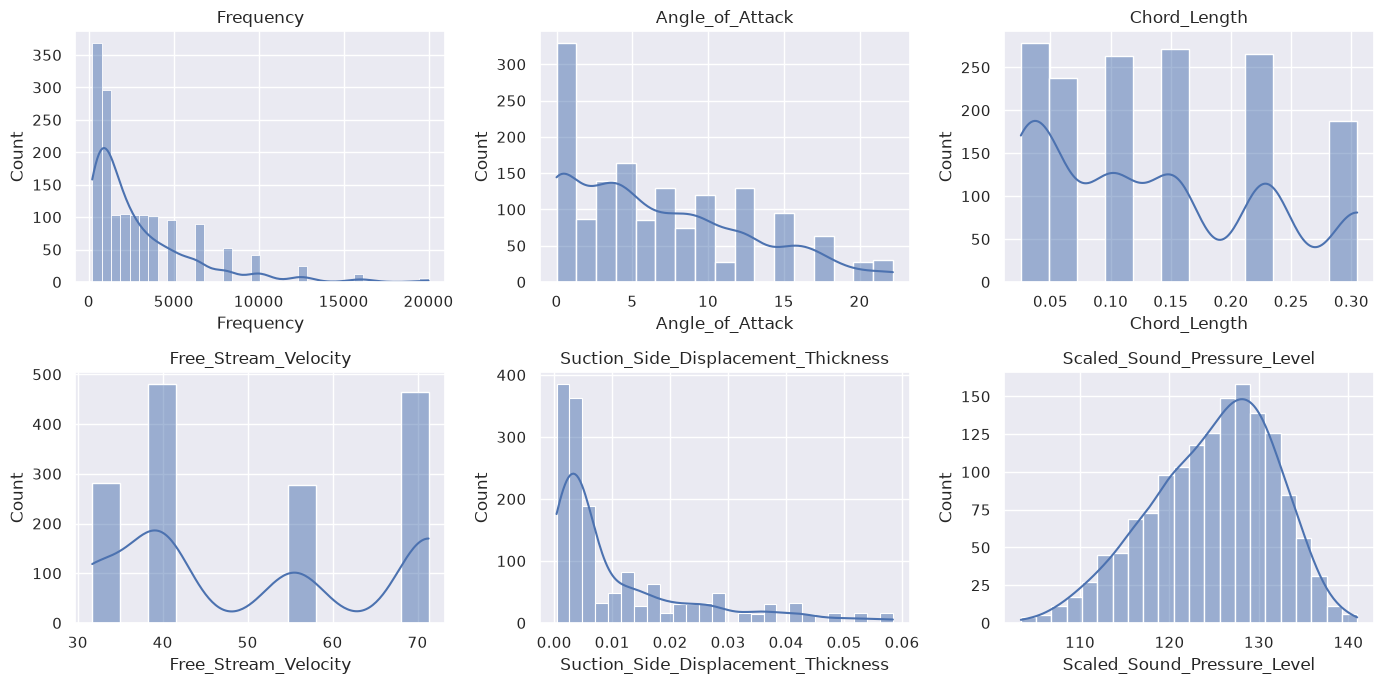

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [25]:
X = df.drop(columns="Scaled_Sound_Pressure_Level")
y = df["Scaled_Sound_Pressure_Level"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print(f"Train: {len(X_train)}  Val: {len(X_val)}  Test: {len(X_test)}")

Train: 901  Val: 301  Test: 301


In [26]:
model = LinearRegression().fit(X_train, y_train)

def report(name, X_, y_):
    pred = model.predict(X_)
    print(f"{name:5s}  MAE={mean_absolute_error(y_, pred):.3f}  "
          f"RMSE={mean_squared_error(y_, pred)**0.5:.3f}  "
          f"R²={r2_score(y_, pred):.3f}")

report("Train", X_train, y_train)
report("Val",   X_val,   y_val)
report("Test",  X_test,  y_test)

Train  MAE=3.760  RMSE=4.854  R²=0.512
Val    MAE=3.653  RMSE=4.741  R²=0.505
Test   MAE=3.707  RMSE=4.717  R²=0.532


In [ ]:
# Turn regression into 3-class classification
y_class = pd.cut(
    y,
    bins=[0, 120, 130, np.inf],
    labels=["quiet", "medium", "loud"],
)

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class,
)

classification_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)
classification_model.fit(X_train_class, y_train_class)
y_pred_class = classification_model.predict(X_test_class)

print(classification_report(y_test_class, y_pred_class))
print("Confusion matrix:")
print(confusion_matrix(y_test_class, y_pred_class))